
# 5. VERİ GÖRSELLEŞTİRME VE İSTATİSTİKSEL ANALIZ

**Proje:** Veri Madenciliği Teknikleri ile IoT/IIoT Ağlarında Siber Saldırı Tespiti ve Sınıflandırılması

**Veri Seti:** Edge-IIoTset

## 5.1. Saldırı Sınıflarının Dağılımı

**Amaç:** Veri setindeki normal trafik ve saldırı sınıflarının dağılımını incelemek.

**Yöntem:** Attack_type değişkenindeki sınıf sayıları ve yüzdeleri hesaplanacak, sonuçlar yatay çubuk grafikle görselleştirilecektir.

**Beklenen Çıktı:** 15 trafik sınıfının kayıt sayılarını ve yüzdelik oranlarını gösteren tablo ve grafik.

**Not:** Çalışma veri setinde azınlık sınıflarını koruyan örnekleme uygulandığından sınıf dağılımı orijinal veri setini birebir temsil etmemektedir.


Toplam kayıt: 399992
Sınıf sayısı: 15


,Kayıt Sayısı,Oran (%)
Attack_type,,
Normal,213783,53.45
DDoS_UDP,61059,15.27
DDoS_ICMP,55581,13.90
DDoS_TCP,38527,9.63
Password,20090,5.02
DDoS_HTTP,4368,1.09
Vulnerability_scanner,2782,0.70
SQL_injection,976,0.24
Uploading,718,0.18


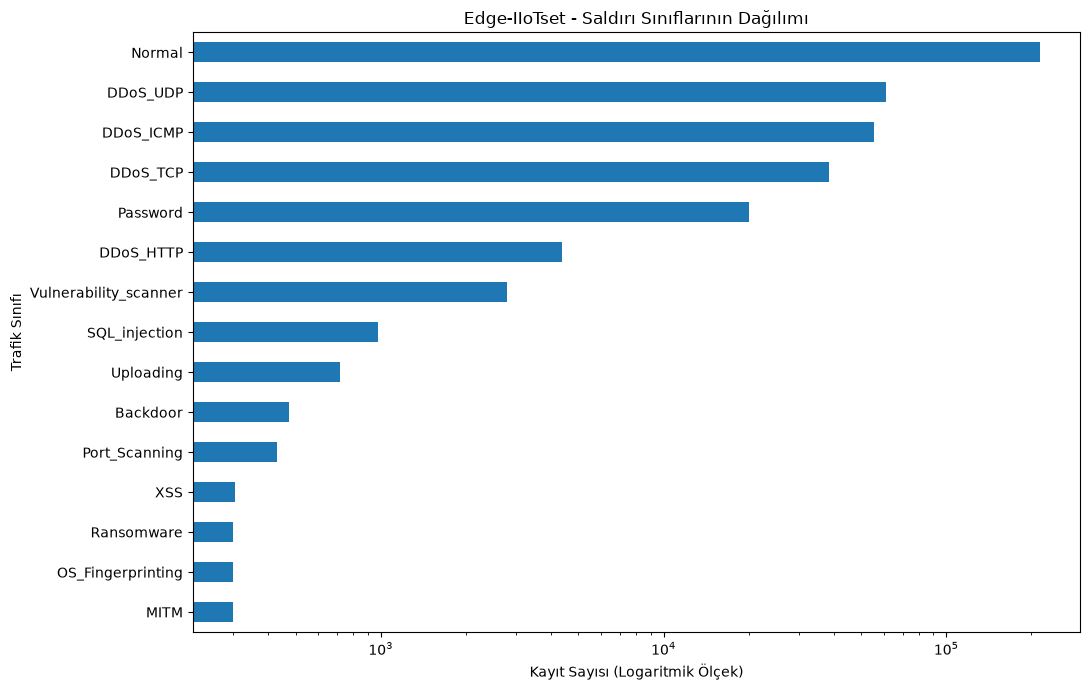

Analiz başarıyla tamamlandı.


In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Proje dosya yolları
proje = Path(r"E:\Data mining\Network_Intrusion_Detection")
dosya = proje / "Calisma_Verileri" / "EdgeIIoT_399992_Son_Temizlik.csv"

# Hedef değişkenini okuma
df = pd.read_csv(dosya, usecols=["Attack_type"])

# Sınıf dağılımı
sayilar = df["Attack_type"].value_counts()

tablo = pd.DataFrame({
    "Kayıt Sayısı": sayilar,
    "Oran (%)": (sayilar / len(df) * 100).round(2)
})

print("Toplam kayıt:", len(df))
print("Sınıf sayısı:", len(sayilar))
display(tablo)

# Grafik
fig, ax = plt.subplots(figsize=(11, 7))

sayilar.sort_values().plot.barh(ax=ax)

ax.set_xscale("log")
ax.set_title("Edge-IIoTset - Saldırı Sınıflarının Dağılımı")
ax.set_xlabel("Kayıt Sayısı (Logaritmik Ölçek)")
ax.set_ylabel("Trafik Sınıfı")

plt.tight_layout()

# Grafiği kaydetme
grafik_klasoru = proje / "Grafikler"
grafik_klasoru.mkdir(parents=True, exist_ok=True)

plt.savefig(
    grafik_klasoru / "05_01_Sinif_Dagilimi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Doğrulama
assert len(df) == 399992
assert len(sayilar) == 15

print("Analiz başarıyla tamamlandı.")



### 5.1. Saldırı Sınıflarının Dağılımı — Sonuç ve Yorum

399.992 kayıt içeren Edge-IIoTset çalışma veri setinde toplam 15 trafik sınıfı bulunmaktadır.

**Analiz Sonuçları:**

- Normal: 213.783 kayıt (%53,45)
- DDoS_UDP: 61.059 kayıt (%15,27)
- DDoS_ICMP: 55.581 kayıt (%13,90)
- DDoS_TCP: 38.527 kayıt (%9,63)
- Password: 20.090 kayıt (%5,02)

MITM, Ransomware ve OS_Fingerprinting sınıflarında ise 300'er kayıt bulunmaktadır.

**Değerlendirme:**

Grafik incelendiğinde Normal trafiğin veri setinde en yüksek orana sahip olduğu görülmektedir. Saldırı türleri arasında ise DDoS_UDP ve DDoS_ICMP sınıfları öne çıkmaktadır.

Sınıflar arasında belirgin bir dağılım dengesizliği bulunmaktadır.

Azınlık sınıflarını koruyan örnekleme yöntemi kullanıldığından, elde edilen sınıf oranları orijinal veri setinin dağılımını birebir temsil etmemektedir.

**Sonuç:**

Sınıf dağılımı analizi tamamlanmıştır. Sınıflar arasındaki dengesizlik nedeniyle model değerlendirme aşamasında Accuracy metriğine ek olarak Macro F1-score, Precision, Recall ve Confusion Matrix kullanılacaktır.



## 5.2. Sayısal Verilerin İstatistiksel Analizi ve Histogram

**Amaç:** Sayısal ağ trafiği özniteliklerinin dağılımlarını ve temel istatistiksel özelliklerini incelemek.

**Yöntem:** `tcp.len`, `tcp.seq`, `udp.time_delta` ve `mbtcp.len` öznitelikleri analiz edilecektir.

Her öznitelik için sıfır, pozitif ve geçersiz değer sayıları hesaplanacaktır. Pozitif ve sonlu değerlerin ortalama, medyan, standart sapma ve maksimum değerleri incelenecektir.

Dağılımlar, sağa çarpık verilerin daha rahat incelenebilmesi amacıyla log(1+x) dönüşümü kullanılarak histogramlarla gösterilecektir. Bu dönüşüm yalnızca görselleştirme amacıyla uygulanacaktır.

**Beklenen Çıktı:** Temel istatistikleri gösteren tablo ve dört özniteliğin dağılım histogramları.

**Not:** Protokole özgü sıfır değerler silinmeyecek, histogramlarda ise pozitif değerlerin dağılımı ayrı incelenecektir.


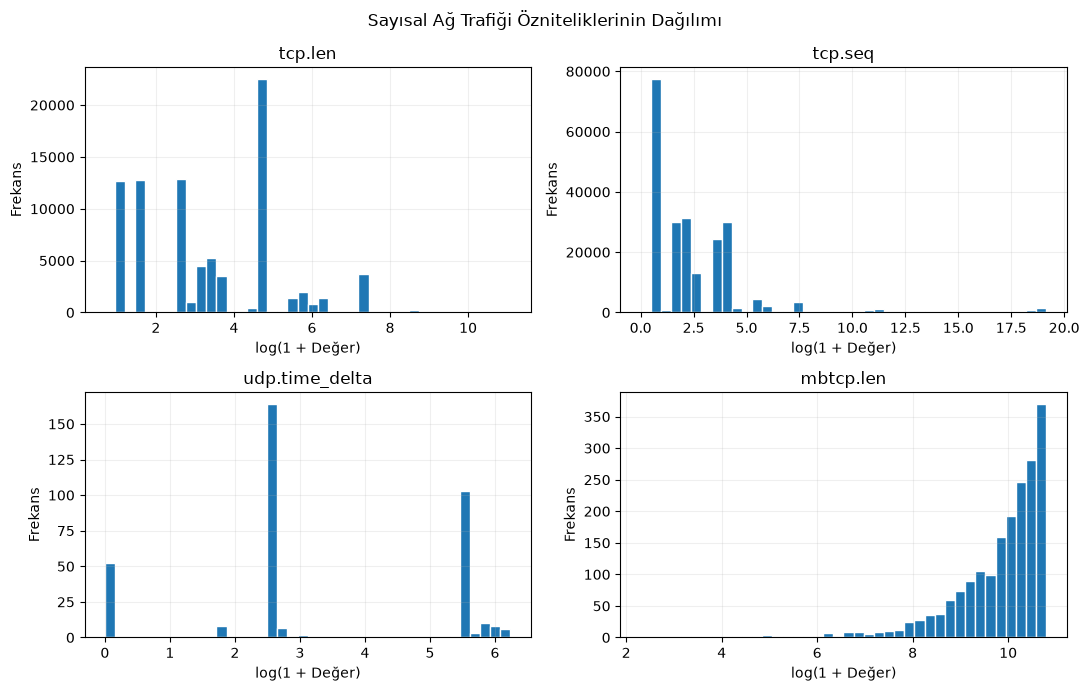

Toplam kayıt: 399992

SAYISAL ÖZNİTELİK İSTATİSTİKLERİ:


,Öznitelik,Sıfır,Pozitif,Geçersiz,Ortalama (+),Medyan (+),Std. Sapma (+),Maksimum (+)
0,tcp.len,314259,85723,10,172.38,25.0,1372.00,65228.0
1,tcp.seq,170787,229205,0,1651682.08,6.0,15035844.25,207879984.0
2,udp.time_delta,399628,364,0,107.43,12.0,136.23,511.0
3,mbtcp.len,398103,1889,0,24507.25,24792.0,14138.69,48876.0



Analiz tamamlandı.


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Veri dosyası
proje = Path(r"E:\Data mining\Network_Intrusion_Detection")
dosya = proje / "Calisma_Verileri" / "EdgeIIoT_399992_Son_Temizlik.csv"

# İncelenecek sayısal öznitelikler
sutunlar = ["tcp.len", "tcp.seq", "udp.time_delta", "mbtcp.len"]

df = pd.read_csv(
    dosya,
    usecols=sutunlar,
    dtype=str,
    na_filter=False
)

istatistikler = []

fig, eksenler = plt.subplots(2, 2, figsize=(11, 7))

for ax, sutun in zip(eksenler.flat, sutunlar):

    sayisal = pd.to_numeric(
        df[sutun].str.strip(),
        errors="coerce"
    )

    sonlu = np.isfinite(sayisal)
    pozitif = sayisal[(sayisal > 0) & sonlu]

    # Temel istatistikler
    istatistikler.append({
        "Öznitelik": sutun,
        "Sıfır": int((sayisal == 0).sum()),
        "Pozitif": len(pozitif),
        "Geçersiz": int((~sonlu).sum()),
        "Ortalama (+)": round(pozitif.mean(), 2),
        "Medyan (+)": round(pozitif.median(), 2),
        "Std. Sapma (+)": round(pozitif.std(), 2),
        "Maksimum (+)": round(pozitif.max(), 2)
    })

    # Pozitif değerler için histogram
    if len(pozitif) > 0:
        ax.hist(np.log1p(pozitif), bins=40, edgecolor="white")
    else:
        ax.text(0.5, 0.5, "Pozitif veri yok",
                ha="center", va="center", transform=ax.transAxes)

    ax.set_title(sutun)
    ax.set_xlabel("log(1 + Değer)")
    ax.set_ylabel("Frekans")
    ax.grid(alpha=0.2)

plt.suptitle("Sayısal Ağ Trafiği Özniteliklerinin Dağılımı")
plt.tight_layout()

# Grafiği kaydetme
grafik_klasoru = proje / "Grafikler"
grafik_klasoru.mkdir(parents=True, exist_ok=True)

plt.savefig(
    grafik_klasoru / "05_02_Sayisal_Histogramlar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# İstatistik tablosu
print("Toplam kayıt:", len(df))
print("\nSAYISAL ÖZNİTELİK İSTATİSTİKLERİ:")
display(pd.DataFrame(istatistikler))

assert len(df) == 399992

print("\nAnaliz tamamlandı.")



### 5.2. Sayısal Verilerin İstatistiksel Analizi ve Histogram — Sonuç ve Yorum

399.992 kayıt içeren Edge-IIoTset çalışma veri setinde dört sayısal özniteliğin istatistiksel özellikleri ve dağılımları incelenmiştir.

#### Analiz Bulguları

| Öznitelik | Sıfır | Pozitif | Geçersiz | Pozitif Medyan |
|---|---:|---:|---:|---:|
| tcp.len | 314.259 | 85.723 | 10 | 25 |
| tcp.seq | 170.787 | 229.205 | 0 | 6 |
| udp.time_delta | 399.628 | 364 | 0 | 12 |
| mbtcp.len | 398.103 | 1.889 | 0 | 24.792 |

#### Değerlendirme

Histogramlar incelendiğinde özniteliklerin farklı dağılım özelliklerine sahip olduğu görülmüştür.

`tcp.len` özniteliğinde pozitif değerlerin ortalaması 172,38, medyanı ise 25 olarak hesaplanmıştır. Bu farklılık, yüksek değerlerin ortalamayı etkilediğini göstermektedir.

`tcp.seq` özniteliğinde pozitif değerlerin medyanı 6 olmasına rağmen maksimum değer 207.879.984'tür. Bu durum, geniş bir değer aralığına işaret etmektedir.

`udp.time_delta` ve `mbtcp.len` özniteliklerinde sıfır değerler büyük çoğunluğu oluşturmaktadır.

Görselleştirmede pozitif değerlere log(1+x) dönüşümü uygulanmış, ancak veri setindeki orijinal değerler değiştirilmemiştir.

#### Sonuç

İncelenen sayısal özniteliklerde sıfır yoğunluğu ve dağılım farklılıkları belirlenmiştir.

Bu bulgular, modelleme aşamasında özniteliklere uygun dönüşüm yöntemlerinin değerlendirilmesi gerektiğini göstermektedir.

Bununla birlikte sayısal olarak geçerli değerlerin tamamının protokol açısından doğru olduğu varsayılamaz. Özellikle `mbtcp.len` gibi alanlarda anlamsal tutarlılık konusu modelleme öncesinde dikkate alınacaktır.

Bu aşamada herhangi bir kayıt silinmemiş veya değiştirilmemiştir.



## 5.3. Boxplot ile Dağılım ve Aykırı Değer Analizi

**Amaç:** Sayısal özniteliklerin merkezi dağılımlarını, değişkenliklerini ve aykırı değer adaylarını görselleştirmek.

**Yöntem:** tcp.len, tcp.seq, udp.time_delta ve mbtcp.len özniteliklerinin pozitif ve sonlu değerleri kullanılacaktır.

Öncelikle orijinal pozitif değerler üzerinde IQR yöntemiyle aykırı değer adayları hesaplanacaktır.

Ardından log(1+x) dönüşümü uygulanarak kutu grafikleri oluşturulacaktır. Grafiklerdeki kutu sınırları dönüştürülmüş dağılıma aittir.

**Beklenen Çıktı:** Dört boxplot grafiği ve aykırı değer adaylarının sayılarını gösteren tablo.

**Not:** Aykırı değerler silinmeyecek ve kaynak veri değiştirilmeyecektir.


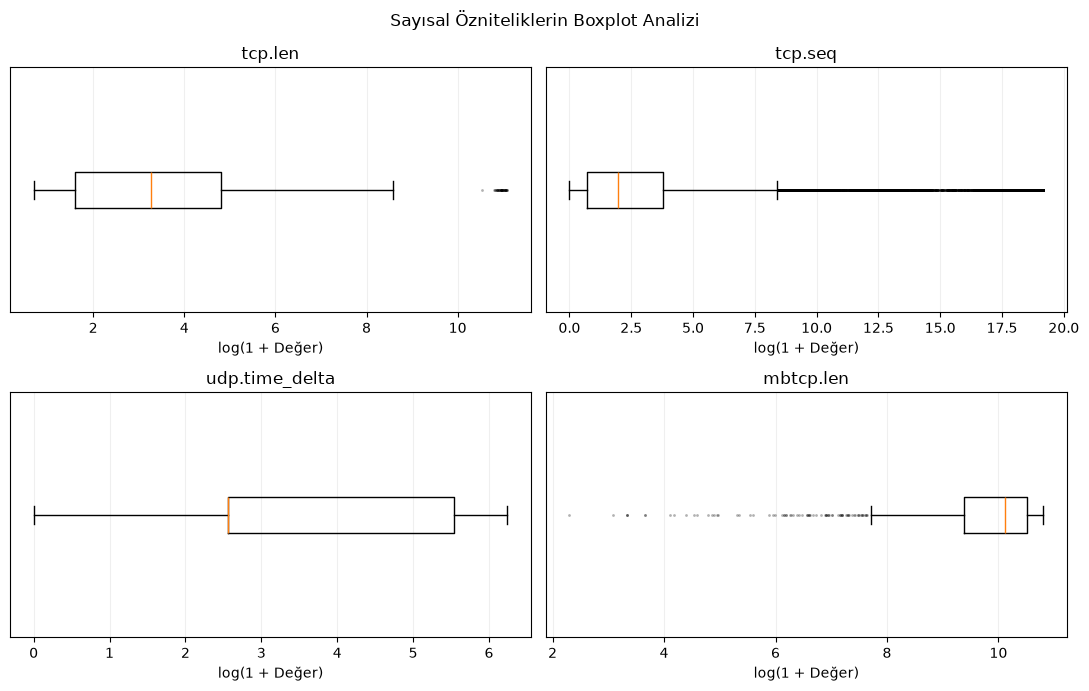

AYKIRI DEĞER ANALİZİ:


,Öznitelik,Pozitif Kayıt,Aykırı Adayı,Oran (%)
0,tcp.len,85723,7972,9.30
1,tcp.seq,229205,20902,9.12
2,udp.time_delta,364,0,0.00
3,mbtcp.len,1889,0,0.00


Analiz tamamlandı.


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

proje = Path(r"E:\Data mining\Network_Intrusion_Detection")
dosya = proje / "Calisma_Verileri" / "EdgeIIoT_399992_Son_Temizlik.csv"

sutunlar = ["tcp.len", "tcp.seq", "udp.time_delta", "mbtcp.len"]

df = pd.read_csv(dosya, usecols=sutunlar, dtype=str)

fig, eksenler = plt.subplots(2, 2, figsize=(11, 7))
sonuclar = []

for ax, sutun in zip(eksenler.flat, sutunlar):

    # Geçerli pozitif değerleri seçme
    sayisal = pd.to_numeric(df[sutun], errors="coerce")
    pozitif = sayisal[(sayisal > 0) & np.isfinite(sayisal)]

    # Orijinal değerlerde IQR analizi
    q1 = pozitif.quantile(0.25)
    q3 = pozitif.quantile(0.75)
    iqr = q3 - q1

    alt = q1 - 1.5 * iqr
    ust = q3 + 1.5 * iqr

    aykiri = ((pozitif < alt) | (pozitif > ust)).sum()

    sonuclar.append({
        "Öznitelik": sutun,
        "Pozitif Kayıt": len(pozitif),
        "Aykırı Adayı": int(aykiri),
        "Oran (%)": round(aykiri / len(pozitif) * 100, 2)
    })

    # Görselleştirme için log dönüşümü
    ax.boxplot(
        np.log1p(pozitif),
        orientation="horizontal",
        flierprops={"marker": ".", "markersize": 2, "alpha": 0.3}
    )

    ax.set_title(sutun)
    ax.set_xlabel("log(1 + Değer)")
    ax.set_yticks([])
    ax.grid(axis="x", alpha=0.2)

fig.suptitle("Sayısal Özniteliklerin Boxplot Analizi")
plt.tight_layout()

# Grafiği kaydetme
grafik_klasoru = proje / "Grafikler"
grafik_klasoru.mkdir(parents=True, exist_ok=True)

plt.savefig(
    grafik_klasoru / "05_03_Boxplot_Analizi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("AYKIRI DEĞER ANALİZİ:")
display(pd.DataFrame(sonuclar))

assert len(df) == 399992
print("Analiz tamamlandı.")



### 5.3. Boxplot Analizi — Sonuç ve Yorum

399.992 kayıtlık Edge-IIoTset veri setinde dört sayısal öznitelik üzerinde kutu grafiği ve IQR analizi uygulanmıştır.

#### Elde Edilen Bulgular

| Öznitelik | Pozitif Kayıt | Aykırı Değer Adayı | Oran (%) |
|---|---:|---:|---:|
| tcp.len | 85.723 | 7.972 | 9,30 |
| tcp.seq | 229.205 | 20.902 | 9,12 |
| udp.time_delta | 364 | 0 | 0 |
| mbtcp.len | 1.889 | 0 | 0 |

#### Değerlendirme

`tcp.len` ve `tcp.seq` özniteliklerinde istatistiksel aykırı değer adayları belirlenmiştir.

`udp.time_delta` ve `mbtcp.len` özniteliklerinde ise pozitif değerler üzerinde uygulanan IQR yöntemine göre aykırı değer adayı tespit edilmemiştir.

Kutu grafiklerinde log(1+x) dönüşümü kullanılmıştır. Bu nedenle grafiklerdeki aykırı noktalar ile orijinal değerlerden hesaplanan IQR sonuçları birebir aynı olmayabilir.

Ayrıca sıfır değerler bu analiz kapsamına alınmamıştır.

#### Sonuç

Sayısal özniteliklerin dağılımları ve aykırı değer adayları incelenmiştir.

Siber saldırı tespitinde olağan dışı trafik değerleri önemli olabileceğinden herhangi bir aykırı değer silinmemiştir.

Veri seti değiştirilmeden korunmuştur.



## 5.4. Korelasyon Analizi

**Amaç:** Sayısal ağ trafiği öznitelikleri arasındaki ilişkileri incelemek.

**Yöntem:** Seçilen yedi sayısal öznitelik üzerinde Spearman korelasyon analizi uygulanacaktır. Sonuçlar korelasyon matrisi ve ısı haritası (Heatmap) ile gösterilecektir.

**Beklenen Çıktı:** Öznitelikler arasındaki pozitif ve negatif ilişkileri gösteren korelasyon tablosu ve grafik.

**Not:** Protokole bağlı sıfır yoğunluğu korelasyon sonuçlarını etkileyebilir. Korelasyon, nedensellik anlamına gelmez. Hedef değişkenler analize dahil edilmeyecektir.


SPEARMAN KORELASYON MATRİSİ:


,tcp.dstport,tcp.len,tcp.seq,tcp.srcport,udp.port,udp.time_delta,mbtcp.len
tcp.dstport,1.000,0.065,0.584,-0.008,-0.038,-0.038,-0.001
tcp.len,0.065,1.000,0.127,0.287,0.049,0.051,-0.035
tcp.seq,0.584,0.127,1.000,0.307,-0.010,-0.009,0.118
tcp.srcport,-0.008,0.287,0.307,1.000,-0.007,-0.009,-0.101
udp.port,-0.038,0.049,-0.010,-0.007,1.000,0.986,-0.002
udp.time_delta,-0.038,0.051,-0.009,-0.009,0.986,1.000,-0.002
mbtcp.len,-0.001,-0.035,0.118,-0.101,-0.002,-0.002,1.000


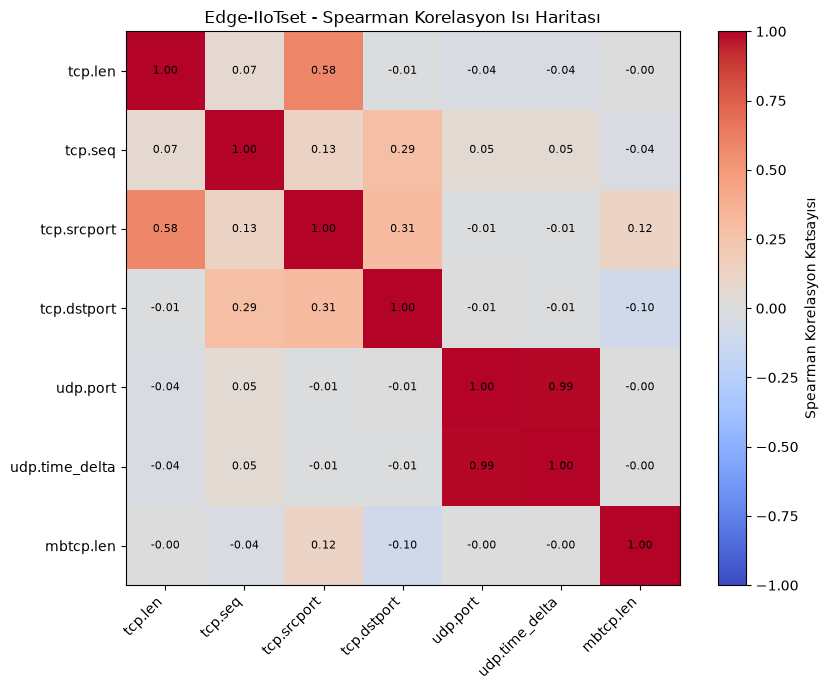

Korelasyon analizi tamamlandı.


In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Veri seti
proje = Path(r"E:\Data mining\Network_Intrusion_Detection")
dosya = proje / "Calisma_Verileri" / "EdgeIIoT_399992_Son_Temizlik.csv"

# Sayısal öznitelikler
sutunlar = [
    "tcp.len",
    "tcp.seq",
    "tcp.srcport",
    "tcp.dstport",
    "udp.port",
    "udp.time_delta",
    "mbtcp.len"
]

df = pd.read_csv(dosya, usecols=sutunlar, dtype=str)

# Sayısal dönüşüm
for sutun in sutunlar:
    df[sutun] = pd.to_numeric(
        df[sutun], errors="coerce"
    )

# Sonsuz değerleri eksik olarak işaretleme
df = df.replace([np.inf, -np.inf], np.nan)

# Spearman korelasyon matrisi
korelasyon = df.corr(
    method="spearman",
    min_periods=100
)

print("SPEARMAN KORELASYON MATRİSİ:")
display(korelasyon.round(3))

# Isı haritası
fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(
    korelasyon,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(sutunlar)))
ax.set_yticks(range(len(sutunlar)))

ax.set_xticklabels(sutunlar, rotation=45, ha="right")
ax.set_yticklabels(sutunlar)

# Korelasyon değerlerini hücrelere yazma
for i in range(len(sutunlar)):
    for j in range(len(sutunlar)):
        deger = korelasyon.iloc[i, j]
        if pd.notna(deger):
            ax.text(
                j, i, f"{deger:.2f}",
                ha="center", va="center", fontsize=8
            )

fig.colorbar(im, ax=ax, label="Spearman Korelasyon Katsayısı")

ax.set_title("Edge-IIoTset - Spearman Korelasyon Isı Haritası")
plt.tight_layout()

# Grafiği kaydetme
grafik_klasoru = proje / "Grafikler"
grafik_klasoru.mkdir(parents=True, exist_ok=True)

plt.savefig(
    grafik_klasoru / "05_04_Korelasyon_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

assert len(df) == 399992

print("Korelasyon analizi tamamlandı.")



### 5.4. Korelasyon Analizi — Sonuç ve Yorum

399.992 kayıt içeren Edge-IIoTset çalışma veri setinde seçilen yedi sayısal öznitelik arasındaki ilişkiler Spearman korelasyon yöntemiyle incelenmiştir.

#### Elde Edilen Bulgular

- udp.port ve udp.time_delta: 0,986
- tcp.dstport ve tcp.seq: 0,584
- tcp.seq ve tcp.srcport: 0,307
- tcp.len ve tcp.srcport: 0,287

Diğer birçok öznitelik çifti arasında sıfıra yakın korelasyon katsayıları gözlemlenmiştir.

#### Değerlendirme

En yüksek korelasyon, udp.port ve udp.time_delta öznitelikleri arasında belirlenmiştir.

Bununla birlikte her iki öznitelikte de yoğun sıfır değerler bulunması, bu ilişkinin protokol özelliklerinden etkilenmiş olabileceğini düşündürmektedir.

tcp.dstport ve tcp.seq arasında orta düzeyde pozitif ilişki tespit edilmiştir.

Korelasyon katsayıları öznitelikler arasındaki monoton ilişkileri göstermektedir; nedensellik veya özniteliklerin birbirinin yerine kullanılabileceğini kanıtlamamaktadır.

Analiz yalnızca seçilmiş yedi sayısal özniteliği kapsamaktadır.

#### Sonuç

Sayısal öznitelikler arasındaki ilişkiler korelasyon matrisi ve ısı haritası kullanılarak incelenmiştir.

Yüksek korelasyona sahip öznitelikler belirlenmiş, ancak bu aşamada herhangi bir öznitelik silinmemiştir.

Özniteliklerin model performansına katkısı, eğitim verileri üzerinde gerçekleştirilecek Feature Selection aşamasında değerlendirilecektir.
